# **MÓDULO 17 - Projeto de Credit Score - Parte 1 - Processamento dos dados**


Essa é a primeira etapa do processo de Credit Score que vocês desenvolverão durante nosso curso.
Nessa primeira etapa vocês irão aplicar os passos aprendidos nos módulos de pré processamento para preparar a base de vocês para o desenvolvimento do modelo.

O termo "credit score" se refere a uma pontuação numérica que representa a credibilidade de um indivíduo em termos de cumprimento de obrigações financeiras, como pagar contas de empréstimos, cartões de crédito, entre outros. Essa pontuação é calculada com base em diversas informações financeiras e de crédito do indivíduo, como histórico de pagamentos, níveis de endividamento, tempo de crédito, tipos de crédito utilizados, entre outros.

O objetivo de um modelo de credit score é prever o risco de um indivíduo se tornar inadimplente com suas obrigações financeiras. Em outras palavras, o modelo avalia a probabilidade de um indivíduo não cumprir com os pagamentos de empréstimos ou outros compromissos financeiros. Essa previsão é fundamental para instituições financeiras, como bancos e credores, na tomada de decisão sobre a concessão de crédito. Um modelo de credit score eficaz pode ajudar essas instituições a avaliar o risco de emprestar dinheiro a um determinado indivíduo e, assim, tomar decisões mais informadas sobre a aprovação ou negação de crédito, bem como sobre os termos e condições desses empréstimos.

**Atenção:** Notem que esse projeto é diferente da base que tenho trabalhado com vocês em aula, apesar de se tratar de uma base bancária durante a aula falamos sobre a variável Churn a ser prevista, nesse caso a previsão seria do valor do Score de Crédito.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import seaborn as sns

In [2]:
# Lembrem-se sempre de alterar a importação dos dados de acordo com o diretório de vocês.
df = pd.read_csv("CREDIT_SCORE_PROJETO_PARTE1.csv", delimiter=";")

df.head(10)

,Age,Gender,Income,Education,Marital Status,Number of Children,Home Ownership,Credit Score
0,25.0,Female,"50.000,00",Bachelor's Degree,Single,0,Rented,High
1,30.0,Male,"100.000,00",Master's Degree,Married,2,Owned,High
2,35.0,Female,"75.000,00",Doctorate,Married,1,Owned,High
3,40.0,Male,"125.000,00",High School Diploma,Single,0,Owned,High
4,45.0,Female,"100.000,00",Bachelor's Degree,Married,3,Owned,High
5,50.0,Male,"150.000,00",Master's Degree,Married,0,Owned,High
6,26.0,Female,"40.000,00",Associate's Degree,Single,0,Rented,Average
7,31.0,Male,"60.000,00",Bachelor's Degree,Single,0,Rented,Average
8,NaN,Female,"80.000,00",Master's Degree,Married,2,Owned,High
9,NaN,Male,"105.000,00",Doctorate,Single,0,Owned,High


Legenda dos dados:

*   **Age** : Idade dos nossos clientes.

*   **Income** : Salário Mensal.

*   **Gender** : Gênero.

*   **Education** : Nível de escolaridade dos clientes.

*   **Marital** : Status Civilmente.

*   **Number of Children** : Quantidade de filhos.

*   **Home** : Tipo de residência, alugada ou própria.

*   **Credit Score** : Nossa variável preditora, o score de crédito dos clientes.


# Etapa 1: Relize os passos que vimos no módulo 18, de pré processamento dos dados.

**A) Verifique os tipos de dados, fazendo as transformações quando necessário.**


In [3]:
df.dtypes

Age                   float64
Gender                    str
Income                    str
Education                 str
Marital Status            str
Number of Children      int64
Home Ownership            str
Credit Score              str
dtype: object

In [4]:
# df["Age"] = df["Age"].astype("int") -> precisa de ajuste mas parece ter valores nulos
df["Income"] = df["Income"].str.replace(".", "").str.replace(",", ".").astype("float")

df.dtypes

Age                   float64
Gender                    str
Income                float64
Education                 str
Marital Status            str
Number of Children      int64
Home Ownership            str
Credit Score              str
dtype: object

**B) Verifique se temos colunas com dados faltantes.
Caso existam colunas com dados faltantes faça o tratamento desses dados, excluindo ou substituindo esses valores. Justifique sua escolha.**

In [5]:
# Numero de colunas nulas
df.isnull().sum()

Age                   34
Gender                 0
Income                 0
Education              0
Marital Status         0
Number of Children     0
Home Ownership         0
Credit Score           0
dtype: int64

In [6]:
# Quanto em porcentagem essas linhas representam
df["Age"].isnull().mean() * 100

np.float64(20.73170731707317)

In [7]:
# Detalhes das linhas com idade faltante
df_age_null = df[df["Age"].isnull()]

df_age_null

,Age,Gender,Income,Education,Marital Status,Number of Children,Home Ownership,Credit Score
8,NaN,Female,80000.0,Master's Degree,Married,2,Owned,High
9,NaN,Male,105000.0,Doctorate,Single,0,Owned,High
10,NaN,Female,90000.0,High School Diploma,Married,1,Owned,High
11,NaN,Male,135000.0,Bachelor's Degree,Married,0,Owned,High
12,NaN,Female,35000.0,High School Diploma,Single,0,Rented,Low
13,NaN,Male,55000.0,Associate's Degree,Single,0,Rented,Average
14,NaN,Female,70000.0,Bachelor's Degree,Married,2,Owned,High
15,NaN,Male,95000.0,Master's Degree,Single,0,Owned,High
16,NaN,Female,85000.0,Doctorate,Married,1,Owned,High
17,NaN,Male,125000.0,High School Diploma,Married,0,Owned,High


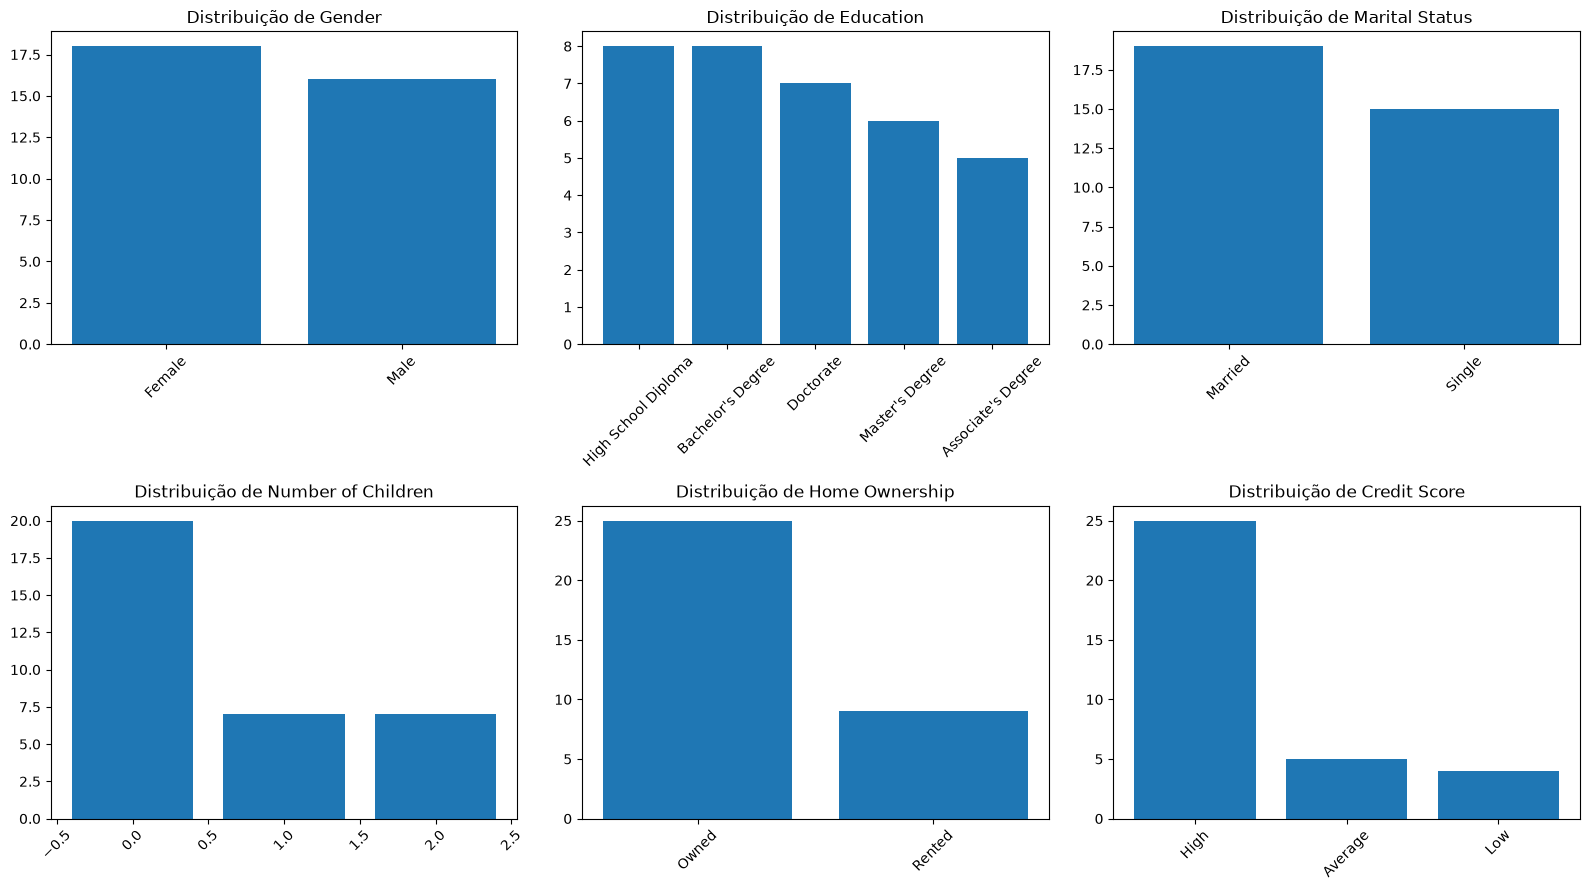

In [8]:
# Checagem para confirmar se existe padrão nas linhdas com dados faltantes
categories = [  # colunas categóricas
    "Gender",
    "Education",
    "Marital Status",
    "Number of Children",
    "Home Ownership",
    "Credit Score",
]


def plotbar(arr):  # função para o loop de plotbar
    plt.bar(arr.index, arr.values)


# Tamanho do plot
plt.figure(figsize=(16, 9))

# loop para subplots
for i in range(len(categories)):  # range pra index e subplot position
    plt.subplot(2, 3, i + 1)
    plt.title(f"Distribuição de {categories[i]}")
    plotbar(df_age_null[categories[i]].value_counts())
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Nos graficos acima fica bem evidente como a remoção de 20% dos dados que as linhas com idade nula representa, podem afetar a análise.
Justo na coluna chave que queremos fazer a predição, as colunas com idade falntante possui em maioria o Score High.
Ou seja, iriamos remover ~25 perfis que se encaixam como High, sem contar a distribuição de donos de casas próprias e com nehuma criança.
Ou seja, acredito que a melhor solução seria a de preencher os dados de idade.

count    130.000000
mean      37.507692
std        8.500110
min       25.000000
25%       30.000000
50%       36.000000
75%       45.000000
max       53.000000
Name: Age, dtype: float64


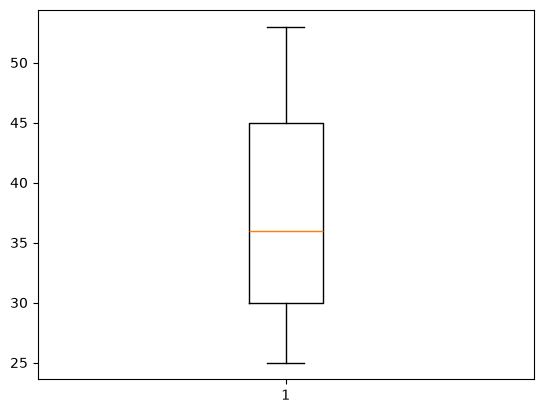

In [9]:
# df com idades validas
df_age_validas = df[df["Age"].notnull()]

# conferindo detalhes da coluna
print(df_age_validas["Age"].describe())

# plot da candle
plt.boxplot(df_age_validas["Age"])
plt.show()

Podemos ver acima que apesar da distribuição se concentrar pouco mais acima da mediana, o .dercribe indica que a Média (~37) e Mediana (36), não são tão distantes.
Acredito que a escolha de qualquer uma das duas seria valida para preservar a integridade do df. Eu vou optar pela média pois acredito que ela vai ser a que vai ter menor impacto geral.

In [10]:
# Ajustando o typo da coluna agora que ela esta sem valores nulos.
df["Age"] = df["Age"].fillna(df["Age"].mean()).astype(int)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 164 entries, 0 to 163
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 164 non-null    int64  
 1   Gender              164 non-null    str    
 2   Income              164 non-null    float64
 3   Education           164 non-null    str    
 4   Marital Status      164 non-null    str    
 5   Number of Children  164 non-null    int64  
 6   Home Ownership      164 non-null    str    
 7   Credit Score        164 non-null    str    
dtypes: float64(1), int64(2), str(5)
memory usage: 10.4 KB


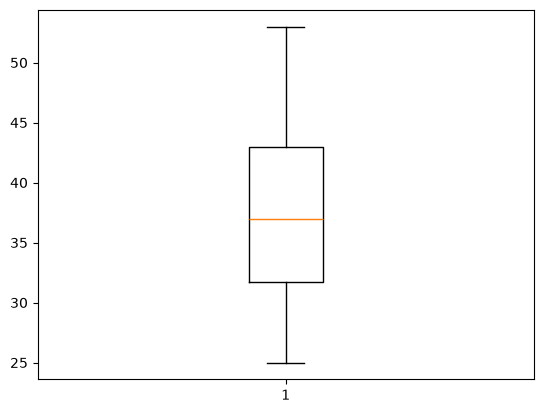

In [11]:
# Conferindo distribuição após ajuste
plt.boxplot(df["Age"])
plt.show()

Colunas com tipos de dados ajustados, sem dados nulos e sem perda de pontos de dado importantes que pudessem prejudicara coluna de target do projeto.

**C) Verifique se temos valores digitados de forma incorreta nas variáveis categóricas que necessitem de tratamento.**

In [12]:
# Agora com as colunas com dados corretos eu posso selecionar caso tipo seja str
df_cat = df.select_dtypes(str)

# Print das colunas categóricas e seus valores unicos
for col in df_cat:
    print(f"{col}\n {df[col].unique()} \n")

Gender
 <StringArray>
['Female', 'Male']
Length: 2, dtype: str 

Education
 <StringArray>
[  'Bachelor's Degree',     'Master's Degree',           'Doctorate',
 'High School Diploma',  'Associate's Degree']
Length: 5, dtype: str 

Marital Status
 <StringArray>
['Single', 'Married']
Length: 2, dtype: str 

Home Ownership
 <StringArray>
['Rented', 'Owned']
Length: 2, dtype: str 

Credit Score
 <StringArray>
['High', 'Average', 'Low']
Length: 3, dtype: str 



Ao que parece, não existem erros de digitação, duplicatas ou similar dentro dos colunas categoricas.

# Etapa 2: Relize os passos que vimos no módulo 15, de análise.

**A) Realiza a análise univariada, aplique a função describe ao nosso dataframe para verificar os dados das variáveis numéricas, se encontrar a possível presença de outliers analise com gráficos a distribuição dos dados.Traga insights sobre os dados analisados.**

In [13]:
# seu código aqui

**B) Agora realize a análise univariada para as variaveis categóricas, plote gráficos para entender a distribuição das categorias e tente retirar insights de cada gráfico.**

In [14]:
# seu código aqui

**C) Você encontrou alguma coluna com outliers?
Se sim realize o tratamento desses casos.**

In [15]:
# seu código aqui

**D) Realize a análise Bivariada.
Tente responder as seguintes perguntas com gráficos seguidos de insights:**



*   Existe relação entre a idade e o status civil?
*   Qual a relação entre o score de crédito e o nível de escolaridade?
*  O salário parece influenciar na idade?
* O salário parece influenciar no Score de Crédito?
* Clientes com casa própria tendem a ter um score mais alto?



In [16]:
# seu código aqui

**E) Que outras perguntas te parecem fazer sentido explorarmos a resposta para conhecermos mais nossa base de dados e o comportamento dos clientes?**

 Elabore mais 3 perguntas e responda utilizando gráficos + insights.

In [17]:
# seu código aqui

# Etapa 3: Relize os passos que vimos no módulo 17, de Correlação, Balanceamento, atributos categóricos e divisão base treino e teste.

**A) Vamos começar pela análise de correlação, plote da forma que achar melhor a análise de correlação, seja pela tabela ou pelo gráfico da matriz.**

In [18]:
# seu código aqui

**B) Você encontrou variáveis que tem uma média ou alta correlação? Se sim, quais? Te parece fazer sentido essas variáveis terem alta correlação? Justifique.**

In [19]:
# sua justificativa aqui

**C) Temos muitos atributos categóricos nessa base, não? Vamos realizar a o tratamento desses atributos utilizando Label Encoder ou one hot. Após, exclua as colunas categóricas.**

In [20]:
# seu código aqui

**D) Vamos plotar novamente a correlação, agora observando com as variáveis categóricas. Identifique se temos novas variáveis com forte correlação.**

In [21]:
# seu código aqui

**F) Faça a separação da base em treino e teste e verifique utilizando shape:**

In [22]:
# seu código aqui

**G) É hora de verificar se nossa coluna de Score de crédito está balanceada, verifique através de um gráfico e traga sua opinião acerca do balanceamento.**

In [23]:
# seu código aqui

**H) Vamos realizar o balancecamento dos dados da coluna de credit score.**
Se lembre que realizazmos apenas para a base de treino.

In [24]:
# seu código aqui